In [7]:
%pip install qiskit qiskit-aer matplotlib
%pip install pylatexenc

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
f_R = 24.79e9
Omega_R = 2 * np.pi * f_R
delta = Omega_R / 2
Omega_eff = np.sqrt(Omega_R**2 + delta**2)
f_eff = Omega_eff / (2 * np.pi)
alpha = np.arctan2(Omega_R, -delta)

In [5]:
#Definicion de el circuito cuántico
def rabi_circuit(t):
    qc = QuantumCircuit(1, 1)
    qc.x(0)
    qc.ry(-alpha, 0)
    qc.rz(Omega_eff * t, 0)
    qc.ry(alpha, 0)
    qc.measure(0, 0)
    return qc

In [9]:
simulator = AerSimulator()
shots = 4096
times = np.linspace(0, 5 * T, 200)
circuits = [rabi_circuit(t) for t in times]
result = simulator.run(circuits, shots=shots).result()
P1 = []
P2 = []
for i in range(len(times)):
    counts = result.get_counts(i)
    P1.append(counts.get("0", 0) / shots)
    P2.append(counts.get("1", 0) / shots)

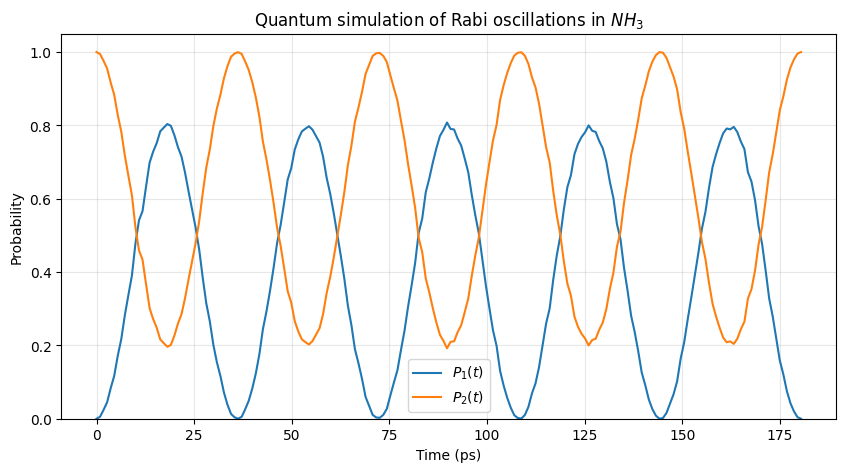

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(times * 1e12, P1, label=r"$P_1(t)$")
plt.plot(times * 1e12, P2, label=r"$P_2(t)$")
plt.xlabel("Time (ps)")
plt.ylabel("Probability")
plt.title(r"Quantum simulation of Rabi oscillations in $NH_3$")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()